In [1]:
import pandas as pd
from PyQt5.QtCore.QByteArray import startsWith

df = pd.read_csv('C:/Users/Arsh/Documents/aiAgents/phase1/data/data.csv', encoding='ISO-8859-1')
print(df.shape) #no rows and columns
print(df.head()) #what indvidual records look like
print(df.tail())
print(df.info()) #column types and not null counts
print(df.isnull().sum()) #missing value in each column

(541909, 8)
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

      InvoiceDate  UnitPrice  CustomerID         Country  
0  12/1/2010 8:26       2.55     17850.0  United Kingdom  
1  12/1/2010 8:26       3.39     17850.0  United Kingdom  
2  12/1/2010 8:26       2.75     17850.0  United Kingdom  
3  12/1/2010 8:26       3.39     17850.0  United Kingdom  
4  12/1/2010 8:26       3.39     17850.0  United Kingdom  
       InvoiceNo StockCode                      Description  Quantity  \
541904    581587     22613      PACK OF 20 SPACEBOY NAPKINS        12   
541905    581587     22899     CHILDREN'S APRON DOLLY G

In [3]:
# check unique customers
print("Unique customers:", df["CustomerID"].nunique())

Unique customers: 4372


In [4]:
#finding missing percentage of missing customerID customers
missing_percentage = df["CustomerID"].isnull().mean() * 100
print(f"Missing CustomerIDs: {missing_percentage:.2f}%")

Missing CustomerIDs: 24.93%


In [18]:
cancelled = df[
    (df['InvoiceNo'].astype(str).str.startswith("C")) &
    (df['Quantity'] < -9)
]
#filter cancelled orders
print(len(cancelled), cancelled["CustomerID"].nunique())


1842 543


In [19]:
print("Total rows:", len(df))
print("Unique invoices:", df["InvoiceNo"].nunique())
print("Unique products:", df["StockCode"].nunique())
print("Unique customers:", df["CustomerID"].nunique())

print("Not Cancelled Orders:", (df["Quantity"] > 0).sum())
print("Cancelled Orders:", (df["Quantity"] < 0).sum())
print("Zero quantity rows:", (df["Quantity"] == 0).sum())

Total rows: 541909
Unique invoices: 25900
Unique products: 4070
Unique customers: 4372
Not Cancelled Orders: 531285
Cancelled Orders: 10624
Zero quantity rows: 0


In [20]:
print("Cancelled invoice rows:",
      df["InvoiceNo"].astype(str).str.startswith("C").sum())

Cancelled invoice rows: 9288


In [21]:
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

print(df[["InvoiceNo", "Quantity", "UnitPrice", "Revenue"]].head(10))

  InvoiceNo  Quantity  UnitPrice  Revenue
0    536365         6       2.55    15.30
1    536365         6       3.39    20.34
2    536365         8       2.75    22.00
3    536365         6       3.39    20.34
4    536365         6       3.39    20.34
5    536365         2       7.65    15.30
6    536365         6       4.25    25.50
7    536366         6       1.85    11.10
8    536366         6       1.85    11.10
9    536367        32       1.69    54.08


In [22]:
is_cancelled = df["InvoiceNo"].astype(str).str.startswith("C")

# Normal invoices
sales = df[~is_cancelled]

# Cancelled invoices
cancelled = df[is_cancelled]

print("Normal invoice rows:", len(sales))
print("Cancelled invoice rows:", len(cancelled))

print("Normal invoice value:", sales["Revenue"].sum())
print("Cancelled invoice value:", cancelled["Revenue"].sum())

Normal invoice rows: 532621
Cancelled invoice rows: 9288
Normal invoice value: 10644560.424000002
Cancelled invoice value: -896812.49


In [25]:
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"],
    errors="coerce"
)

print(df["InvoiceDate"].dtype)

datetime64[ns]


In [28]:
is_cancelled = df["InvoiceNo"].astype(str).str.startswith("C")
sales = df[~is_cancelled].copy()

In [29]:
monthly_revenue = (
    sales.groupby(
        sales["InvoiceDate"].dt.to_period("M")
    )["Revenue"]
    .sum()
)

print(monthly_revenue)

InvoiceDate
2010-12     823746.140
2011-01     691364.560
2011-02     523631.890
2011-03     717639.360
2011-04     537808.621
2011-05     770536.020
2011-06     761739.900
2011-07     719221.191
2011-08     737014.260
2011-09    1058590.172
2011-10    1154979.300
2011-11    1509496.330
2011-12     638792.680
Freq: M, Name: Revenue, dtype: float64


In [30]:
monthly_analysis = monthly_revenue.to_frame(name="Revenue")

monthly_analysis["Previous_Revenue"] = (
    monthly_analysis["Revenue"].shift(1)
)

monthly_analysis["Change"] = (
    monthly_analysis["Revenue"]
    - monthly_analysis["Previous_Revenue"]
)

monthly_analysis["Growth_Percentage"] = (
    monthly_analysis["Change"]
    / monthly_analysis["Previous_Revenue"]
    * 100
)

print(monthly_analysis.round(2))

                Revenue  Previous_Revenue     Change  Growth_Percentage
InvoiceDate                                                            
2010-12       823746.14               NaN        NaN                NaN
2011-01       691364.56         823746.14 -132381.58             -16.07
2011-02       523631.89         691364.56 -167732.67             -24.26
2011-03       717639.36         523631.89  194007.47              37.05
2011-04       537808.62         717639.36 -179830.74             -25.06
2011-05       770536.02         537808.62  232727.40              43.27
2011-06       761739.90         770536.02   -8796.12              -1.14
2011-07       719221.19         761739.90  -42518.71              -5.58
2011-08       737014.26         719221.19   17793.07               2.47
2011-09      1058590.17         737014.26  321575.91              43.63
2011-10      1154979.30        1058590.17   96389.13               9.11
2011-11      1509496.33        1154979.30  354517.03            

In [33]:
declines = monthly_analysis[monthly_analysis["Change"] < 0]
if not declines.empty:
    worst_month = declines["Change"].idxmin()
    print("Month with Largest Decline:", worst_month)
    print("Revenue Changed: ", declines.loc[worst_month, "Change"].round(2))
    print("Growth percentage: ", declines.loc[worst_month, "Growth_Percentage"].round(2))

Month with Largest Decline: 2011-12
Revenue Changed:  -870703.65
Growth percentage:  -57.68


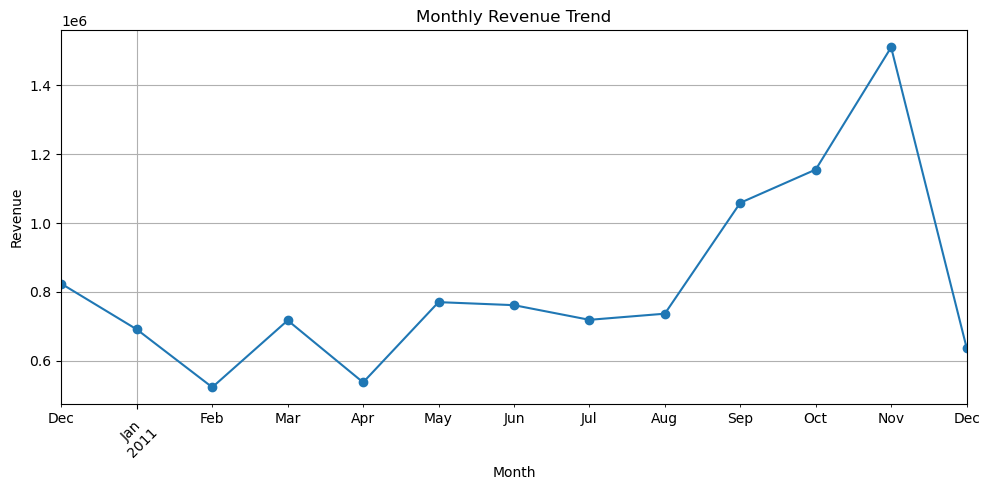

In [34]:
import matplotlib.pyplot as plt

monthly_analysis["Revenue"].plot(
    kind="line",
    marker="o",
    figsize=(10, 5)
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [35]:
worst_month = monthly_analysis["Change"].idxmin()
previous_month = worst_month-1
df["Month"] = df["InvoiceDate"].dt.to_period("M") #filter the data for both months
comparsion = df[
    (~df["InvoiceNo"].astype(str).str.startswith("C")) &
    (df["Month"].isin([previous_month, worst_month]))
].copy()
country_revenue = comparsion.pivot_table(
    index = "Country",
    columns = "Month",
    values = "Revenue",
    aggfunc="sum",
    fill_value=0
) # this helps oragnise revenue by Country and Month
country_revenue["Change"] = (country_revenue[worst_month] - country_revenue[previous_month])
#new column called change
print(country_revenue.sort_values("Change").head(10))

Month              2011-11    2011-12     Change
Country                                         
United Kingdom  1325346.21  592622.09 -732724.12
France            31758.71    7276.92  -24481.79
EIRE              30738.43    7340.89  -23397.54
Germany           28025.02    7984.17  -20040.85
Netherlands       25874.01   11728.02  -14145.99
Japan              8460.08       0.00   -8460.08
Spain              8678.96     316.21   -8362.75
Switzerland        8118.96       0.00   -8118.96
Australia          7242.72       0.00   -7242.72
Belgium            6315.76    1417.73   -4898.03


In [37]:
country_revenue["Percentage Change"] = (country_revenue["Change"] / country_revenue[previous_month])*100

In [42]:
drops = country_revenue[
    country_revenue["Percentage Change"] < 0
]
print(drops.sort_values("Percentage Change").head(69).round(2))

Month               2011-11    2011-12     Change  Percentage Change
Country                                                             
Australia           7242.72       0.00   -7242.72            -100.00
Switzerland         8118.96       0.00   -8118.96            -100.00
Poland              1361.23       0.00   -1361.23            -100.00
Malta                743.43       0.00    -743.43            -100.00
Japan               8460.08       0.00   -8460.08            -100.00
Hong Kong            326.10       0.00    -326.10            -100.00
Cyprus               460.89       0.00    -460.89            -100.00
Unspecified          965.75       0.00    -965.75            -100.00
Spain               8678.96     316.21   -8362.75             -96.36
Italy               4571.08     200.45   -4370.63             -95.61
Denmark             2699.57     168.90   -2530.67             -93.74
Sweden              2722.23     238.00   -2484.23             -91.26
Channel Islands     1514.77     19

In [43]:
print(drops.sort_values(by=["Percentage Change", "Change"], ascending=[True, True]).head(69).round(2))

Month               2011-11    2011-12     Change  Percentage Change
Country                                                             
Japan               8460.08       0.00   -8460.08            -100.00
Switzerland         8118.96       0.00   -8118.96            -100.00
Australia           7242.72       0.00   -7242.72            -100.00
Poland              1361.23       0.00   -1361.23            -100.00
Unspecified          965.75       0.00    -965.75            -100.00
Malta                743.43       0.00    -743.43            -100.00
Cyprus               460.89       0.00    -460.89            -100.00
Hong Kong            326.10       0.00    -326.10            -100.00
Spain               8678.96     316.21   -8362.75             -96.36
Italy               4571.08     200.45   -4370.63             -95.61
Denmark             2699.57     168.90   -2530.67             -93.74
Sweden              2722.23     238.00   -2484.23             -91.26
Channel Islands     1514.77     19

In [46]:
worst_country = drops.sort_values(by=["Percentage Change", "Change"], ascending=[True, True]).index[0]
print("Country to Investigate: ", worst_country)

Country to Investigate:  Japan


In [48]:
country_data = comparsion[
    comparsion["Country"] == worst_country
].copy()

print(country_data.head())

       InvoiceNo StockCode               Description  Quantity  \
475847    576923     22660     DOORMAT I LOVE LONDON        50   
475848    576923     20750  RED RETROSPOT MINI CASES        48   
475849    576923     22667     RECIPE BOX RETROSPOT         48   
475850    576923     22911    PAPER CHAIN KIT LONDON        80   
475851    576923     22902    TOTE BAG I LOVE LONDON        50   

               InvoiceDate  UnitPrice  CustomerID Country  Revenue    Month  
475847 2011-11-17 10:52:00       7.08     12753.0   Japan    354.0  2011-11  
475848 2011-11-17 10:52:00       6.35     12753.0   Japan    304.8  2011-11  
475849 2011-11-17 10:52:00       2.55     12753.0   Japan    122.4  2011-11  
475850 2011-11-17 10:52:00       2.55     12753.0   Japan    204.0  2011-11  
475851 2011-11-17 10:52:00       1.69     12753.0   Japan     84.5  2011-11  


In [50]:
is_cancelled = df["InvoiceNo"].astype(str).str.startswith("C")
negative_sales = df[
    (~is_cancelled) &
    (df["Quantity"] < 0)
]
print("Negative Quantity Rows:", len(negative_sales))
print(
    negative_sales[
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "UnitPrice", "InvoiceDate"]
    ].head(10)
)

Negative Quantity Rows: 1336
     InvoiceNo StockCode Description  Quantity  UnitPrice         InvoiceDate
2406    536589     21777         NaN       -10        0.0 2010-12-01 16:50:00
4347    536764    84952C         NaN       -38        0.0 2010-12-02 14:42:00
7188    536996     22712         NaN       -20        0.0 2010-12-03 15:30:00
7189    536997     22028         NaN       -20        0.0 2010-12-03 15:30:00
7190    536998     85067         NaN        -6        0.0 2010-12-03 15:30:00
7192    537000     21414         NaN       -22        0.0 2010-12-03 15:32:00
7193    537001     21653         NaN        -6        0.0 2010-12-03 15:33:00
7195    537003     85126         NaN        -2        0.0 2010-12-03 15:33:00
7196    537004     21814         NaN       -30        0.0 2010-12-03 15:34:00
7197    537005     21692         NaN       -70        0.0 2010-12-03 15:35:00


In [52]:
revenue_total = df.loc[~is_cancelled, "Revenue"].sum()
revenue_positive = df.loc[
    (~is_cancelled) & (df["Quantity"] > 0),
    "Revenue"
].sum()
print(revenue_total)
print(revenue_positive)


10644560.424000002
10644560.424


In [56]:
valid_sales = df[
    (~is_cancelled) &
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0) &
    (df["InvoiceDate"].notna())
].copy()
valid_sales["Revenue"] = (
    valid_sales["Quantity"] * valid_sales["UnitPrice"]
)
monthly_gross_sales = (
    valid_sales.groupby(
        valid_sales["InvoiceDate"].dt.to_period("M")
    )["Revenue"].sum()
)
print(monthly_gross_sales)


InvoiceDate
2010-12     823746.140
2011-01     691364.560
2011-02     523631.890
2011-03     717639.360
2011-04     537808.621
2011-05     770536.020
2011-06     761739.900
2011-07     719221.191
2011-08     759138.380
2011-09    1058590.172
2011-10    1154979.300
2011-11    1509496.330
2011-12     638792.680
Freq: M, Name: Revenue, dtype: float64


In [57]:
revenue_comparison = pd.concat(
    [
        monthly_revenue.rename("Earlier Revenue"),
        monthly_gross_sales.rename("Gross Sales")
    ],
    axis=1,
).fillna(0)

revenue_comparison["Difference"] = (
    revenue_comparison["Gross Sales"] -
    revenue_comparison["Earlier Revenue"]
)
print(revenue_comparison.round(2))

             Earlier Revenue  Gross Sales  Difference
InvoiceDate                                          
2010-12            823746.14    823746.14        0.00
2011-01            691364.56    691364.56        0.00
2011-02            523631.89    523631.89        0.00
2011-03            717639.36    717639.36        0.00
2011-04            537808.62    537808.62        0.00
2011-05            770536.02    770536.02        0.00
2011-06            761739.90    761739.90        0.00
2011-07            719221.19    719221.19        0.00
2011-08            737014.26    759138.38    22124.12
2011-09           1058590.17   1058590.17        0.00
2011-10           1154979.30   1154979.30        0.00
2011-11           1509496.33   1509496.33        0.00
2011-12            638792.68    638792.68        0.00


In [58]:
valid_sales.to_csv(
    "cleaned_online_retail.csv",
    index=False
)